# Travel Insurance Purchase Prediction

## Problem Description and Business Context

In the competitive travel and tourism sector, travel booking platforms and insurance providers strive to protect travelers against unforeseen events including trip cancellations, medical emergencies abroad, and baggage losses. However, indiscriminately presenting insurance offers to every prospective traveler causes digital display fatigue, damages checkout conversion rates, and wastes marketing spend.

Machine learning offers an automated, high precision solution. By analyzing historical traveler demographic profiles, employment stability, household characteristics, and past international travel patterns, a classification model can compute a traveler purchase propensity score in real time.

When a customer searches for flights or proceeds to booking checkout:
1. The customer profile is dispatched to the prediction web service.
2. The service calculates the probability of the customer purchasing travel insurance.
3. High propensity customers are targeted with customized insurance packages and relevant coverage benefits.
4. Low propensity customers experience a frictionless, streamlined checkout flow without irrelevant prompts.

This targeted approach improves insurance conversion, maximizes gross merchandise value, and elevates traveler user experience.


## 1. Environment Setup and Data Loading

We import the required scientific computing, visualization, and machine learning libraries.
The dataset is loaded from the data directory.


In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    mutual_info_score,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

df = pd.read_csv('data/travel_insurance.csv')
print('Dataset shape:', df.shape)
print('Dataset columns:', df.columns.tolist())
df.head()


Matplotlib is building the font cache; this may take a moment.


Dataset shape: (1987, 9)
Dataset columns: ['age', 'employment_type', 'graduate_or_not', 'annual_income', 'family_members', 'chronic_diseases', 'frequent_flyer', 'ever_travelled_abroad', 'travel_insurance']


,age,employment_type,graduate_or_not,annual_income,family_members,chronic_diseases,frequent_flyer,ever_travelled_abroad,travel_insurance
0,31,government_sector,yes,400000,6,1,no,no,0
1,31,private_sector_self_employed,yes,1250000,7,0,no,no,0
2,34,private_sector_self_employed,yes,500000,4,1,no,no,1
3,28,private_sector_self_employed,yes,700000,3,1,no,no,0
4,28,private_sector_self_employed,yes,700000,8,1,yes,no,0


## 2. Data Cleaning and Inspection

We inspect data types, missing values, and summary statistics across all features.


In [2]:
print('Data Types and Non Null Counts:')
print(df.info())

print('\nMissing Value Summary:')
missing_counts = df.isnull().sum()
print(missing_counts)

print('\nSummary Statistics for Numerical Features:')
display(df.describe().T)

print('\nSummary Statistics for Categorical Features:')
display(df.describe(include=['object', 'str']).T)


Data Types and Non Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 1987 entries, 0 to 1986
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   age                    1987 non-null   int64
 1   employment_type        1987 non-null   str  
 2   graduate_or_not        1987 non-null   str  
 3   annual_income          1987 non-null   int64
 4   family_members         1987 non-null   int64
 5   chronic_diseases       1987 non-null   int64
 6   frequent_flyer         1987 non-null   str  
 7   ever_travelled_abroad  1987 non-null   str  
 8   travel_insurance       1987 non-null   int64
dtypes: int64(5), str(4)
memory usage: 202.1 KB
None

Missing Value Summary:
age                      0
employment_type          0
graduate_or_not          0
annual_income            0
family_members           0
chronic_diseases         0
frequent_flyer           0
ever_travelled_abroad    0
travel_insurance         0
dty

,count,mean,std,min,25%,50%,75%,max
age,1987.0,29.650226,2.913308,25.0,28.0,29.0,32.0,35.0
annual_income,1987.0,932762.959235,376855.684748,300000.0,600000.0,900000.0,1250000.0,1800000.0
family_members,1987.0,4.752894,1.609650,2.0,4.0,5.0,6.0,9.0
chronic_diseases,1987.0,0.277806,0.448030,0.0,0.0,0.0,1.0,1.0
travel_insurance,1987.0,0.357323,0.479332,0.0,0.0,0.0,1.0,1.0



Summary Statistics for Categorical Features:


,count,unique,top,freq
employment_type,1987,2,private_sector_self_employed,1417
graduate_or_not,1987,2,yes,1692
frequent_flyer,1987,2,no,1570
ever_travelled_abroad,1987,2,no,1607


## 3. Target Variable Analysis

The target variable is travel_insurance:
0 indicates the customer did not purchase travel insurance.
1 indicates the customer purchased travel insurance.

We analyze the class balance and baseline conversion rate.


Target Counts:
travel_insurance
0    1277
1     710
Name: count, dtype: int64

Target Percentages:
travel_insurance
0    64.26774
1    35.73226
Name: proportion, dtype: float64


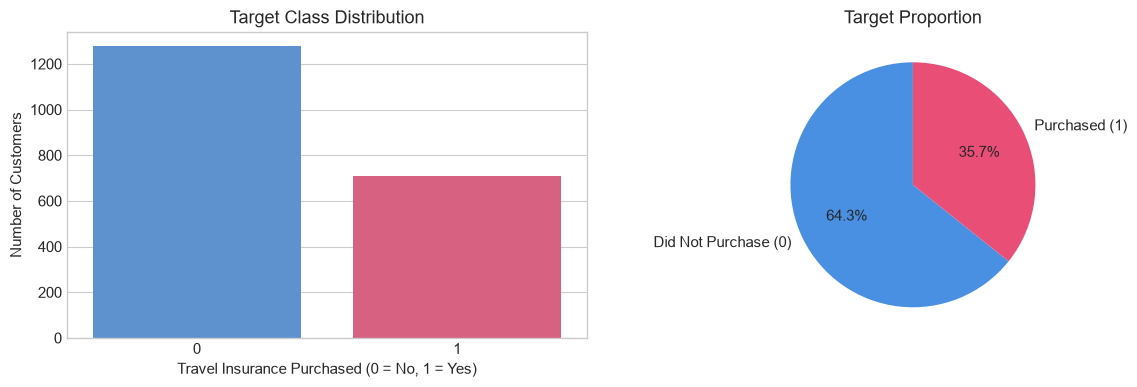

In [3]:
target_counts = df['travel_insurance'].value_counts()
target_percent = df['travel_insurance'].value_counts(normalize=True) * 100

print('Target Counts:')
print(target_counts)
print('\nTarget Percentages:')
print(target_percent)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='travel_insurance', data=df, ax=axes[0], palette=['#4A90E2', '#E94E77'])
axes[0].set_title('Target Class Distribution')
axes[0].set_xlabel('Travel Insurance Purchased (0 = No, 1 = Yes)')
axes[0].set_ylabel('Number of Customers')

axes[1].pie(
    target_counts,
    labels=['Did Not Purchase (0)', 'Purchased (1)'],
    autopct='%1.1f%%',
    colors=['#4A90E2', '#E94E77'],
    startangle=90
)
axes[1].set_title('Target Proportion')

plt.tight_layout()
plt.show()


## 4. Exploratory Data Analysis: Numerical Features

We inspect numerical features:
1. age: Age of customer (ranges from 25 to 35)
2. annual_income: Annual income in local currency units
3. family_members: Number of members in customer family
4. chronic_diseases: Indicator whether customer suffers from chronic conditions


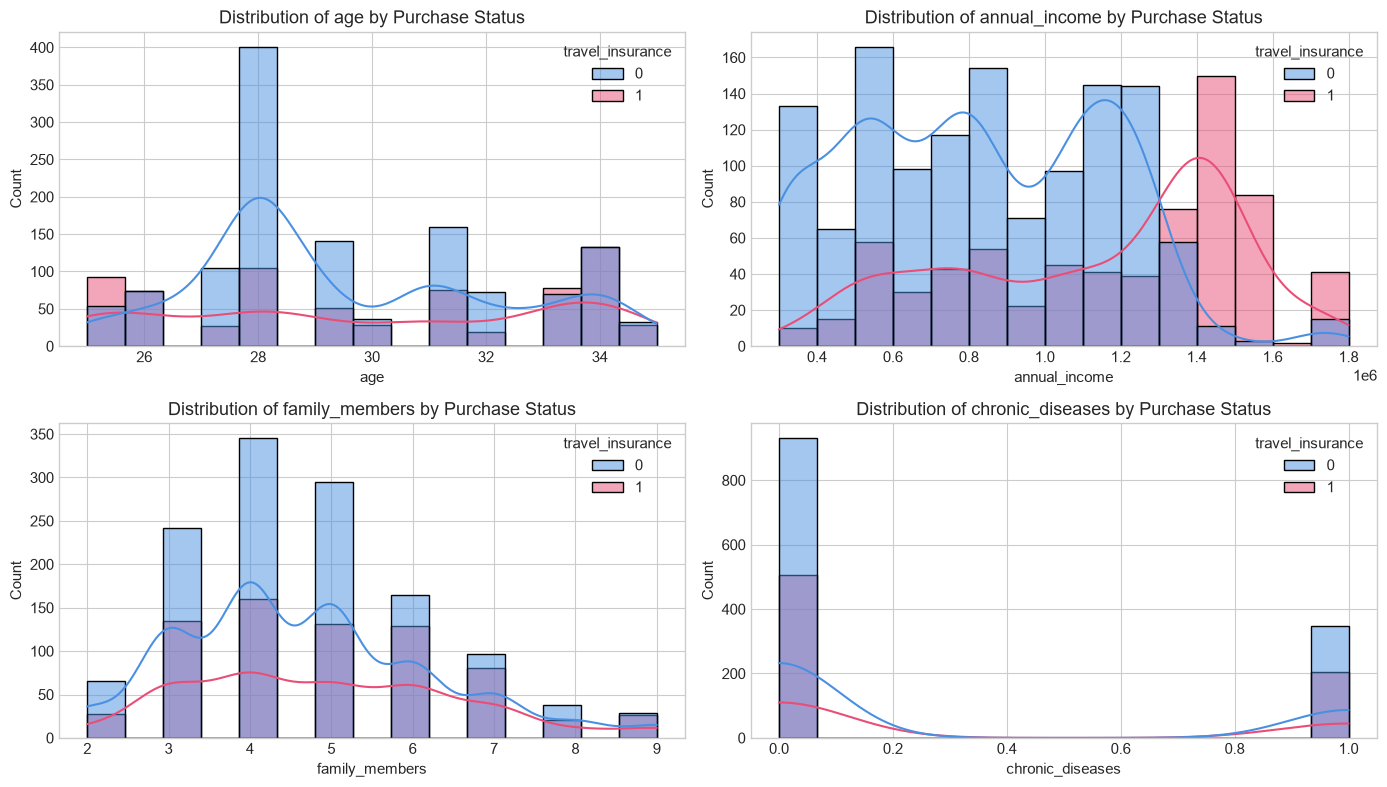

Mean values grouped by purchase outcome:


travel_insurance,0,1
age,29.517619,2.988873e+01
annual_income,821299.921691,1.133239e+06
family_members,4.657009,4.925352e+00
chronic_diseases,0.271731,2.887324e-01


In [4]:
num_cols = ['age', 'annual_income', 'family_members', 'chronic_diseases']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(
        df,
        x=col,
        hue='travel_insurance',
        kde=True,
        ax=axes[i],
        palette=['#4A90E2', '#E94E77'],
        bins=15
    )
    axes[i].set_title(f'Distribution of {col} by Purchase Status')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

print('Mean values grouped by purchase outcome:')
display(df.groupby('travel_insurance')[num_cols].mean().T)


## 5. Exploratory Data Analysis: Categorical Features and Feature Importance

We inspect categorical attributes:
1. employment_type: Private sector self employed versus government sector
2. graduate_or_not: Higher education graduate status
3. frequent_flyer: History of frequent flight bookings
4. ever_travelled_abroad: Past international travel history

We calculate:
1. Purchase conversion rate per category
2. Risk ratio (relative purchase rate compared to global mean)
3. Mutual information score between categorical features and target


Global Travel Insurance Purchase Rate: 0.3573

Category Analysis for employment_type:


,count,mean,risk_ratio,diff_from_global
employment_type,,,,
government_sector,570,0.245614,0.687373,-0.111709
private_sector_self_employed,1417,0.402258,1.125757,0.044936



Category Analysis for graduate_or_not:


,count,mean,risk_ratio,diff_from_global
graduate_or_not,,,,
no,295,0.335593,0.939188,-0.021729
yes,1692,0.361111,1.010603,0.003789



Category Analysis for frequent_flyer:


,count,mean,risk_ratio,diff_from_global
frequent_flyer,,,,
no,1570,0.300000,0.839577,-0.057323
yes,417,0.573141,1.603989,0.215819



Category Analysis for ever_travelled_abroad:


,count,mean,risk_ratio,diff_from_global
ever_travelled_abroad,,,,
no,1607,0.256378,0.717498,-0.100944
yes,380,0.784211,2.194685,0.426888


Mutual Information Scores with Target:
ever_travelled_abroad    0.091751
frequent_flyer           0.025983
employment_type          0.011351
graduate_or_not          0.000181
dtype: float64


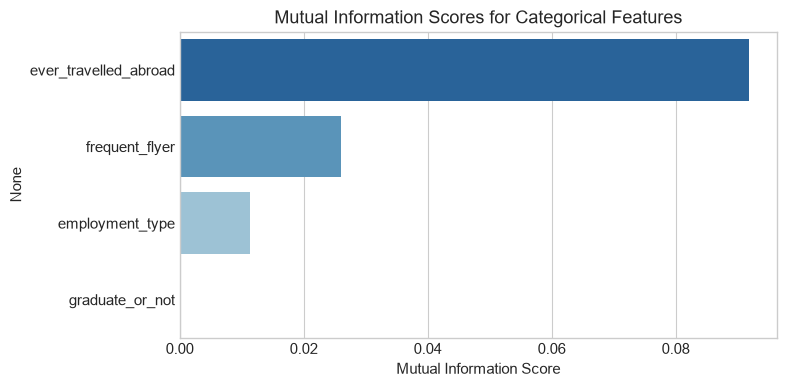

In [5]:
cat_cols = ['employment_type', 'graduate_or_not', 'frequent_flyer', 'ever_travelled_abroad']
global_rate = df['travel_insurance'].mean()
print(f'Global Travel Insurance Purchase Rate: {global_rate:.4f}\n')

for col in cat_cols:
    df_group = df.groupby(col)['travel_insurance'].agg(['count', 'mean'])
    df_group['risk_ratio'] = df_group['mean'] / global_rate
    df_group['diff_from_global'] = df_group['mean'] - global_rate
    print(f'Category Analysis for {col}:')
    display(df_group)
    print()

def calculate_mi(series):
    return mutual_info_score(series, df['travel_insurance'])

mi_scores = df[cat_cols].apply(calculate_mi).sort_values(ascending=False)
print('Mutual Information Scores with Target:')
print(mi_scores)

plt.figure(figsize=(8, 4))
sns.barplot(x=mi_scores.values, y=mi_scores.index, palette='Blues_r')
plt.title('Mutual Information Scores for Categorical Features')
plt.xlabel('Mutual Information Score')
plt.tight_layout()
plt.show()


## 6. Numerical Feature Correlation Matrix

We compute the correlation matrix among numerical features and the target.


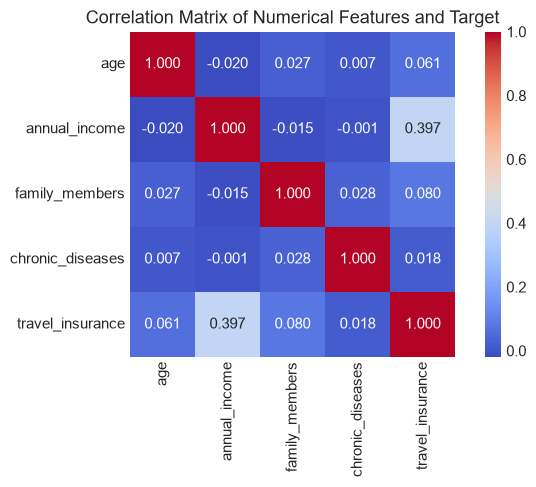

In [6]:
corr_matrix = df[num_cols + ['travel_insurance']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Matrix of Numerical Features and Target')
plt.tight_layout()
plt.show()


## 7. Validation Framework and Data Splitting

We split the dataset into:
1. Training set: 60 percent
2. Validation set: 20 percent
3. Test set: 20 percent

We apply stratified splitting to preserve the class proportion across all splits.
Fixed random state of 42 ensures complete reproducibility.


In [7]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df['travel_insurance']
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=42,
    stratify=df_full_train['travel_insurance']
)

y_train = df_train['travel_insurance'].values
y_val = df_val['travel_insurance'].values
y_test = df_test['travel_insurance'].values

df_train = df_train.drop(columns=['travel_insurance'])
df_val = df_val.drop(columns=['travel_insurance'])
df_test = df_test.drop(columns=['travel_insurance'])

print(f'Full dataset records: {len(df)}')
print(f'Training set records: {len(df_train)} ({len(df_train)/len(df)*100:.1f}%)')
print(f'Validation set records: {len(df_val)} ({len(df_val)/len(df)*100:.1f}%)')
print(f'Test set records: {len(df_test)} ({len(df_test)/len(df)*100:.1f}%)')


Full dataset records: 1987
Training set records: 1191 (59.9%)
Validation set records: 398 (20.0%)
Test set records: 398 (20.0%)


## 8. Feature Encoding with DictVectorizer

We use Scikit Learn DictVectorizer to transform dictionaries of features into numerical matrices.
Categorical variables are automatically one hot encoded while numerical variables remain untouched.


In [8]:
feature_cols = cat_cols + num_cols

train_dict = df_train[feature_cols].to_dict(orient='records')
val_dict = df_val[feature_cols].to_dict(orient='records')
test_dict = df_test[feature_cols].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)
X_test = dv.transform(test_dict)

feature_names = dv.get_feature_names_out()
print('Transformed feature dimension:', X_train.shape[1])
print('Engineered features:')
for name in feature_names:
    print(' ', name)


Transformed feature dimension: 12
Engineered features:
  age
  annual_income
  chronic_diseases
  employment_type=government_sector
  employment_type=private_sector_self_employed
  ever_travelled_abroad=no
  ever_travelled_abroad=yes
  family_members
  frequent_flyer=no
  frequent_flyer=yes
  graduate_or_not=no
  graduate_or_not=yes


## 9. Model 1: Logistic Regression and Regularization Tuning

We train a Logistic Regression model as our linear baseline.
We evaluate the effect of the regularization parameter C across orders of magnitude.


In [9]:
c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lr_results = []

for c in c_values:
    model_lr = LogisticRegression(solver='liblinear', C=c, random_state=42)
    model_lr.fit(X_train, y_train)
    y_pred = model_lr.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    acc = accuracy_score(y_val, y_pred >= 0.5)
    lr_results.append({'C': c, 'AUC': auc, 'Accuracy': acc})

df_lr_results = pd.DataFrame(lr_results)
print('Logistic Regression Tuning Results:')
display(df_lr_results)

best_lr_c = df_lr_results.loc[df_lr_results['AUC'].idxmax()]['C']
final_lr = LogisticRegression(solver='liblinear', C=best_lr_c, random_state=42)
final_lr.fit(X_train, y_train)
y_pred_lr = final_lr.predict_proba(X_val)[:, 1]
lr_auc = roc_auc_score(y_val, y_pred_lr)
print(f'Best Logistic Regression Validation AUC: {lr_auc:.4f} at C={best_lr_c}')


Logistic Regression Tuning Results:


,C,AUC,Accuracy
0,0.001,0.685794,0.660804
1,0.010,0.685794,0.660804
2,0.100,0.685794,0.660804
3,1.000,0.685794,0.660804
4,10.000,0.685794,0.660804
5,100.000,0.685794,0.660804


Best Logistic Regression Validation AUC: 0.6858 at C=0.001


## 10. Model 2: Decision Tree Classifier and Parameter Tuning

We train a Decision Tree Classifier and tune:
1. max_depth: controls the maximum depth of the tree
2. min_samples_leaf: controls the minimum samples required in leaf nodes


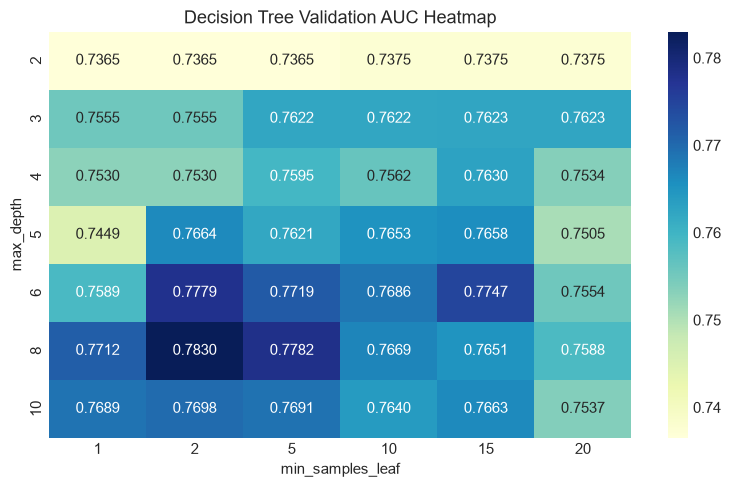

Best Decision Tree parameters:
max_depth           8.000
min_samples_leaf    2.000
AUC                 0.783
Name: 31, dtype: float64
Best Decision Tree Validation AUC: 0.7830


In [10]:
depths = [2, 3, 4, 5, 6, 8, 10]
leafs = [1, 2, 5, 10, 15, 20]
dt_grid = []

for d in depths:
    for s in leafs:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s, random_state=42)
        dt.fit(X_train, y_train)
        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        dt_grid.append({'max_depth': d, 'min_samples_leaf': s, 'AUC': round(auc, 4)})

df_dt_grid = pd.DataFrame(dt_grid)
pivot_dt = df_dt_grid.pivot(index='max_depth', columns='min_samples_leaf', values='AUC')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_dt, annot=True, fmt='.4f', cmap='YlGnBu')
plt.title('Decision Tree Validation AUC Heatmap')
plt.tight_layout()
plt.show()

best_dt_row = df_dt_grid.loc[df_dt_grid['AUC'].idxmax()]
print('Best Decision Tree parameters:')
print(best_dt_row)

best_dt = DecisionTreeClassifier(
    max_depth=int(best_dt_row['max_depth']),
    min_samples_leaf=int(best_dt_row['min_samples_leaf']),
    random_state=42
)
best_dt.fit(X_train, y_train)
y_pred_dt = best_dt.predict_proba(X_val)[:, 1]
dt_auc = roc_auc_score(y_val, y_pred_dt)
print(f'Best Decision Tree Validation AUC: {dt_auc:.4f}')


## 11. Model 3: Random Forest Classifier and Parameter Tuning

We train an ensemble Random Forest Classifier.
We tune:
1. max_depth
2. min_samples_leaf
3. n_estimators


Top parameter combination for Random Forest:
max_depth           4.0000
min_samples_leaf    1.0000
AUC                 0.7674
Name: 4, dtype: float64


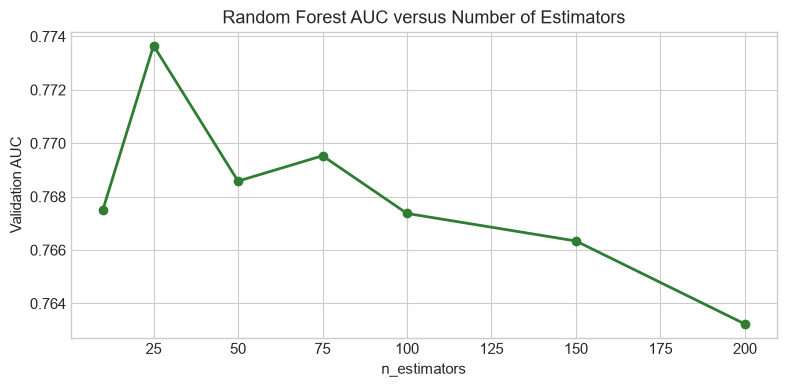

Best Random Forest Validation AUC: 0.7737 with n_estimators=25, max_depth=4, min_samples_leaf=1


In [11]:
rf_depths = [3, 4, 5, 6, 8]
rf_leafs = [1, 3, 5, 10]
rf_results = []

for d in rf_depths:
    for s in rf_leafs:
        rf = RandomForestClassifier(n_estimators=100, max_depth=d, min_samples_leaf=s, random_state=42)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        rf_results.append({'max_depth': d, 'min_samples_leaf': s, 'AUC': round(auc, 4)})

df_rf_grid = pd.DataFrame(rf_results)
best_rf_row = df_rf_grid.loc[df_rf_grid['AUC'].idxmax()]
print('Top parameter combination for Random Forest:')
print(best_rf_row)

best_depth = int(best_rf_row['max_depth'])
best_leaf = int(best_rf_row['min_samples_leaf'])

n_estimators_list = [10, 25, 50, 75, 100, 150, 200]
est_scores = []
for n in n_estimators_list:
    rf = RandomForestClassifier(n_estimators=n, max_depth=best_depth, min_samples_leaf=best_leaf, random_state=42)
    rf.fit(X_train, y_train)
    y_pred = rf.predict_proba(X_val)[:, 1]
    est_scores.append(roc_auc_score(y_val, y_pred))

plt.figure(figsize=(8, 4))
plt.plot(n_estimators_list, est_scores, marker='o', color='#2E7D32', linewidth=2)
plt.title('Random Forest AUC versus Number of Estimators')
plt.xlabel('n_estimators')
plt.ylabel('Validation AUC')
plt.tight_layout()
plt.show()

best_n = n_estimators_list[np.argmax(est_scores)]
best_rf = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, min_samples_leaf=best_leaf, random_state=42)
best_rf.fit(X_train, y_train)
y_pred_rf = best_rf.predict_proba(X_val)[:, 1]
rf_auc = roc_auc_score(y_val, y_pred_rf)
print(f'Best Random Forest Validation AUC: {rf_auc:.4f} with n_estimators={best_n}, max_depth={best_depth}, min_samples_leaf={best_leaf}')


## 12. Model 4: Gradient Boosting with XGBoost and Parameter Tuning

We train an XGBoost model using DMatrix structures.
We tune:
1. max_depth
2. min_child_weight
3. eta (learning rate)
4. num_boost_round


Top XGBoost Hyperparameters:
max_depth           4.000000
min_child_weight    3.000000
eta                 0.030000
AUC                 0.775349
Name: 21, dtype: float64


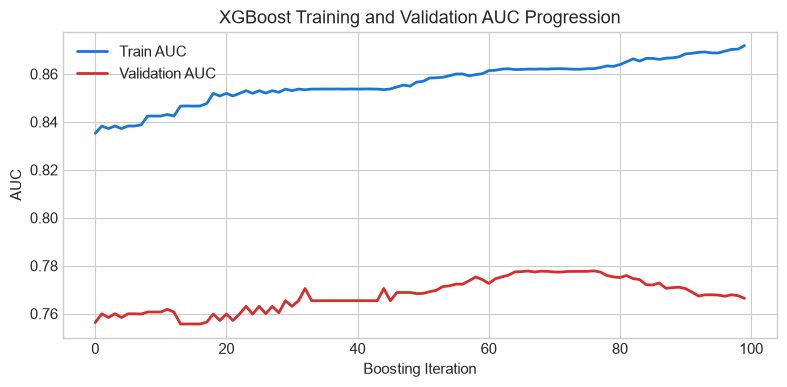

Best XGBoost Validation AUC: 0.7664


In [12]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=list(feature_names))
dval = xgb.DMatrix(X_val, label=y_val, feature_names=list(feature_names))
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=list(feature_names))

xgb_tuning = []
for md in [2, 3, 4]:
    for mcw in [1, 3, 5]:
        for eta in [0.03, 0.05, 0.1]:
            params = {
                'eta': eta,
                'max_depth': md,
                'min_child_weight': mcw,
                'objective': 'binary:logistic',
                'eval_metric': 'auc',
                'seed': 42
            }
            model = xgb.train(params, dtrain, num_boost_round=80)
            score = roc_auc_score(y_val, model.predict(dval))
            xgb_tuning.append({'max_depth': md, 'min_child_weight': mcw, 'eta': eta, 'AUC': score})

df_xgb_tuning = pd.DataFrame(xgb_tuning)
best_xgb_row = df_xgb_tuning.loc[df_xgb_tuning['AUC'].idxmax()]
print('Top XGBoost Hyperparameters:')
print(best_xgb_row)

best_xgb_params = {
    'eta': float(best_xgb_row['eta']),
    'max_depth': int(best_xgb_row['max_depth']),
    'min_child_weight': int(best_xgb_row['min_child_weight']),
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 42
}

evals = [(dtrain, 'train'), (dval, 'val')]
evals_result = {}
best_xgb = xgb.train(
    best_xgb_params,
    dtrain,
    num_boost_round=100,
    evals=evals,
    evals_result=evals_result,
    verbose_eval=False
)

train_auc_history = evals_result['train']['auc']
val_auc_history = evals_result['val']['auc']

plt.figure(figsize=(8, 4))
plt.plot(train_auc_history, label='Train AUC', color='#1976D2', linewidth=2)
plt.plot(val_auc_history, label='Validation AUC', color='#D32F2F', linewidth=2)
plt.title('XGBoost Training and Validation AUC Progression')
plt.xlabel('Boosting Iteration')
plt.ylabel('AUC')
plt.legend()
plt.tight_layout()
plt.show()

y_pred_xgb = best_xgb.predict(dval)
xgb_auc = roc_auc_score(y_val, y_pred_xgb)
print(f'Best XGBoost Validation AUC: {xgb_auc:.4f}')


## 13. Model 5: Gradient Boosting with LightGBM

We also train a LightGBM classifier as an additional gradient boosting alternative.
We tune learning rate and num_leaves.


In [13]:
lgb_train = lgb.Dataset(X_train, label=y_train)
lgb_val = lgb.Dataset(X_val, label=y_val, reference=lgb_train)

lgb_results = []
for lr_rate in [0.03, 0.05, 0.1]:
    for leaves in [7, 15, 31]:
        params = {
            'objective': 'binary',
            'metric': 'auc',
            'learning_rate': lr_rate,
            'num_leaves': leaves,
            'random_state': 42,
            'verbose': -1
        }
        gbm = lgb.train(params, lgb_train, num_boost_round=80)
        score = roc_auc_score(y_val, gbm.predict(X_val))
        lgb_results.append({'learning_rate': lr_rate, 'num_leaves': leaves, 'AUC': score})

df_lgb = pd.DataFrame(lgb_results)
best_lgb_row = df_lgb.loc[df_lgb['AUC'].idxmax()]
print('Top LightGBM Hyperparameters:')
print(best_lgb_row)

best_lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': float(best_lgb_row['learning_rate']),
    'num_leaves': int(best_lgb_row['num_leaves']),
    'random_state': 42,
    'verbose': -1
}
best_lgb = lgb.train(best_lgb_params, lgb_train, num_boost_round=80)
y_pred_lgb = best_lgb.predict(X_val)
lgb_auc = roc_auc_score(y_val, y_pred_lgb)
print(f'Best LightGBM Validation AUC: {lgb_auc:.4f}')


Top LightGBM Hyperparameters:
learning_rate    0.030000
num_leaves       7.000000
AUC              0.773589
Name: 0, dtype: float64
Best LightGBM Validation AUC: 0.7736


## 14. Model Comparison and Selection

We compare all 5 trained models across validation metrics:
1. ROC AUC Score
2. Accuracy
3. Precision
4. Recall
5. F1 Score


Model Validation Comparison Summary:


,Model,ROC AUC,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.7830,0.7990,0.8370,0.5423,0.6581
2,Random Forest,0.7737,0.7789,0.8971,0.4296,0.5810
4,LightGBM,0.7736,0.8065,0.8652,0.5423,0.6667
3,XGBoost,0.7664,0.8065,0.8652,0.5423,0.6667
0,Logistic Regression,0.6858,0.6608,0.8182,0.0634,0.1176


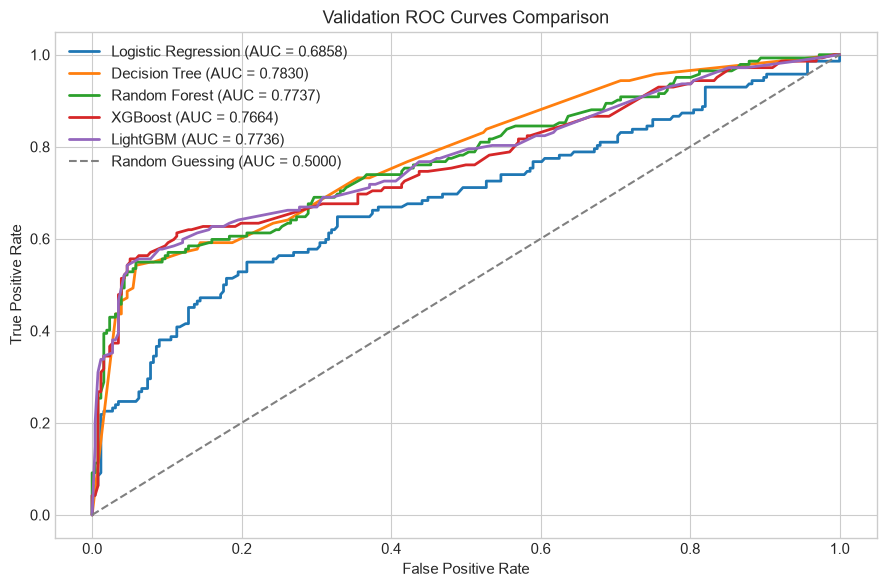

In [14]:
models_preds = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgb
}

comparison_rows = []
for name, preds in models_preds.items():
    binary_preds = preds >= 0.5
    comparison_rows.append({
        'Model': name,
        'ROC AUC': round(roc_auc_score(y_val, preds), 4),
        'Accuracy': round(accuracy_score(y_val, binary_preds), 4),
        'Precision': round(precision_score(y_val, binary_preds), 4),
        'Recall': round(recall_score(y_val, binary_preds), 4),
        'F1 Score': round(f1_score(y_val, binary_preds), 4)
    })

df_comparison = pd.DataFrame(comparison_rows).sort_values(by='ROC AUC', ascending=False)
print('Model Validation Comparison Summary:')
display(df_comparison)

plt.figure(figsize=(9, 6))
for name, preds in models_preds.items():
    fpr, tpr, _ = roc_curve(y_val, preds)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_val, preds):.4f})', linewidth=2)

plt.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random Guessing (AUC = 0.5000)')
plt.title('Validation ROC Curves Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()


## 15. Decision Threshold Tuning and Error Analysis

Default classification threshold is 0.5.
We examine precision, recall, and F1 scores across thresholds from 0.10 to 0.90
to select the optimal operational decision boundary for XGBoost.


Optimal Decision Threshold for Maximum F1: 0.30
At threshold 0.30:
 Precision: 0.8587
 Recall:    0.5563
 F1 Score:  0.6752


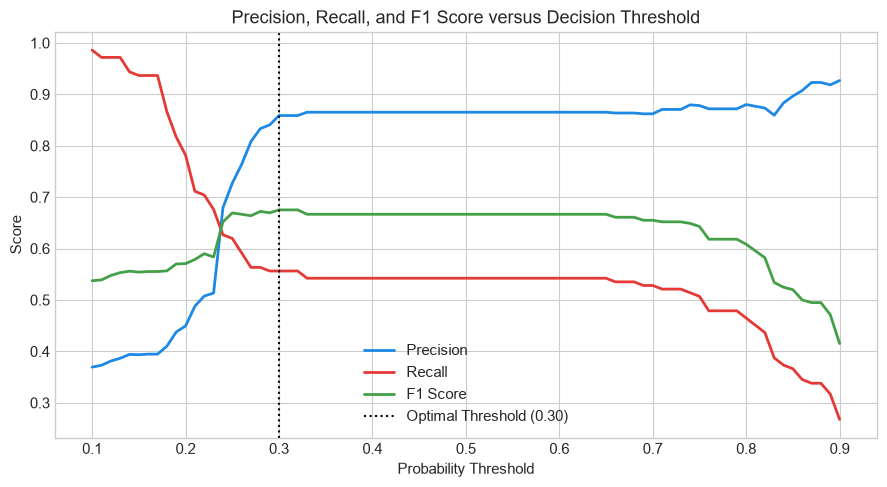

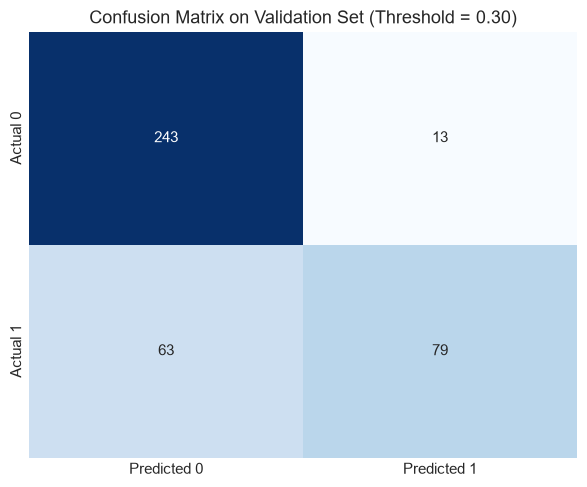


Detailed Classification Report on Validation Set:
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       256
           1       0.86      0.56      0.68       142

    accuracy                           0.81       398
   macro avg       0.83      0.75      0.77       398
weighted avg       0.82      0.81      0.80       398



In [15]:
thresholds = np.linspace(0.1, 0.9, 81)
precisions = []
recalls = []
f1_scores = []

for t in thresholds:
    p = (y_pred_xgb >= t).astype(int)
    precisions.append(precision_score(y_val, p, zero_division=0))
    recalls.append(recall_score(y_val, p, zero_division=0))
    f1_scores.append(f1_score(y_val, p, zero_division=0))

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
print(f'Optimal Decision Threshold for Maximum F1: {best_threshold:.2f}')
print(f'At threshold {best_threshold:.2f}:')
print(f' Precision: {precisions[best_idx]:.4f}')
print(f' Recall:    {recalls[best_idx]:.4f}')
print(f' F1 Score:  {f1_scores[best_idx]:.4f}')

plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label='Precision', color='#1E88E5', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='#E53935', linewidth=2)
plt.plot(thresholds, f1_scores, label='F1 Score', color='#43A047', linewidth=2)
plt.axvline(best_threshold, color='black', linestyle=':', label=f'Optimal Threshold ({best_threshold:.2f})')
plt.title('Precision, Recall, and F1 Score versus Decision Threshold')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()

opt_preds = (y_pred_xgb >= best_threshold).astype(int)
cm = confusion_matrix(y_val, opt_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title(f'Confusion Matrix on Validation Set (Threshold = {best_threshold:.2f})')
plt.tight_layout()
plt.show()

print('\nDetailed Classification Report on Validation Set:')
print(classification_report(y_val, opt_preds))


## 16. Feature Importance Analysis

We examine which features most strongly influence travel insurance purchase predictions in XGBoost.


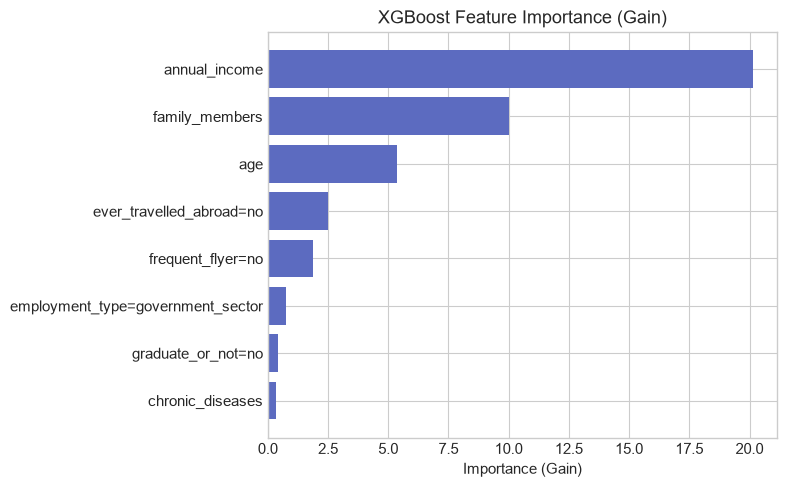

Feature Importance Table:


,feature,importance
1,annual_income,20.135075
5,family_members,9.996152
0,age,5.355923
4,ever_travelled_abroad=no,2.488981
6,frequent_flyer=no,1.857171
3,employment_type=government_sector,0.733727
7,graduate_or_not=no,0.439895
2,chronic_diseases,0.349852


In [16]:
importance_dict = best_xgb.get_score(importance_type='gain')
df_importance = pd.DataFrame(
    list(importance_dict.items()),
    columns=['feature', 'importance']
).sort_values(by='importance', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(df_importance['feature'], df_importance['importance'], color='#5C6BC0')
plt.title('XGBoost Feature Importance (Gain)')
plt.xlabel('Importance (Gain)')
plt.tight_layout()
plt.show()

print('Feature Importance Table:')
display(df_importance.sort_values(by='importance', ascending=False))


## 17. Final Model Training and Test Set Evaluation

We train the selected XGBoost model on the full training dataset (train + validation).
Then we evaluate performance on the held out test dataset to confirm generalization.


In [17]:
y_full_train = df_full_train['travel_insurance'].values
df_full_train_features = df_full_train.drop(columns=['travel_insurance'])

full_train_dict = df_full_train_features[feature_cols].to_dict(orient='records')
test_dict = df_test[feature_cols].to_dict(orient='records')

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(full_train_dict)
X_test_final = dv_final.transform(test_dict)

dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=list(dv_final.get_feature_names_out()))
dtest_final = xgb.DMatrix(X_test_final, label=y_test, feature_names=list(dv_final.get_feature_names_out()))

final_xgb_model = xgb.train(
    best_xgb_params,
    dfulltrain,
    num_boost_round=80
)

y_test_pred = final_xgb_model.predict(dtest_final)
test_auc = roc_auc_score(y_test, y_test_pred)
test_acc = accuracy_score(y_test, y_test_pred >= best_threshold)
test_f1 = f1_score(y_test, y_test_pred >= best_threshold)

print('Final Model Performance on Held Out Test Set:')
print(f' Test ROC AUC:  {test_auc:.4f}')
print(f' Test Accuracy: {test_acc:.4f}')
print(f' Test F1 Score: {test_f1:.4f}')

print('\nDetailed Classification Report on Held Out Test Set:')
print(classification_report(y_test, y_test_pred >= best_threshold))


Final Model Performance on Held Out Test Set:
 Test ROC AUC:  0.7927
 Test Accuracy: 0.8141
 Test F1 Score: 0.6838

Detailed Classification Report on Held Out Test Set:
              precision    recall  f1-score   support

           0       0.80      0.95      0.87       256
           1       0.87      0.56      0.68       142

    accuracy                           0.81       398
   macro avg       0.83      0.76      0.78       398
weighted avg       0.82      0.81      0.80       398



## 18. Saving Final Model to Binary File

We save the trained DictVectorizer, the final XGBoost model, and the optimal decision threshold into model.bin.
We then reload the file and verify inference on two sample customer dictionaries.


In [18]:
output_file = 'model.bin'
with open(output_file, 'wb') as f_out:
    pickle.dump((dv_final, final_xgb_model, best_threshold), f_out)

print(f'Model successfully saved to {output_file}')

with open(output_file, 'rb') as f_in:
    dv_loaded, model_loaded, threshold_loaded = pickle.load(f_in)

customer_high_risk = {
    'age': 34,
    'employment_type': 'private_sector_self_employed',
    'graduate_or_not': 'yes',
    'annual_income': 1400000,
    'family_members': 6,
    'chronic_diseases': 0,
    'frequent_flyer': 'yes',
    'ever_travelled_abroad': 'yes'
}

customer_low_risk = {
    'age': 28,
    'employment_type': 'government_sector',
    'graduate_or_not': 'yes',
    'annual_income': 400000,
    'family_members': 3,
    'chronic_diseases': 0,
    'frequent_flyer': 'no',
    'ever_travelled_abroad': 'no'
}

for label, cust in [('High Propensity Customer', customer_high_risk), ('Low Propensity Customer', customer_low_risk)]:
    X_cust = dv_loaded.transform([cust])
    dcust = xgb.DMatrix(X_cust, feature_names=list(dv_loaded.get_feature_names_out()))
    prob = float(model_loaded.predict(dcust)[0])
    decision = bool(prob >= threshold_loaded)
    print(f'\n{label}:')
    print(f' Purchase Probability: {prob:.4f}')
    print(f' Targeted for Insurance: {decision}')


Model successfully saved to model.bin

High Propensity Customer:
 Purchase Probability: 0.8822
 Targeted for Insurance: True

Low Propensity Customer:
 Purchase Probability: 0.1162
 Targeted for Insurance: False
